# 04 · Baselines and Model Selection
Course phases **7 (baseline establishment)** and **8A (model selection)**.

**Builds on:** `fdp.data` (01), `fdp.preprocess` (02), `fdp.features` (03).
**Files produced:** `src/fdp/baselines.py`, `reports/04_model_selection.json`, and `reports/figures/04_*.png`.

Run the cells in order in Colab, Jupyter or VS Code. Locally, install `requirements.txt` in the notebook's Python environment first. Set `QUICK_RUN = False` for final results. On macOS, XGBoost also requires `brew install libomp`. Local setup is in the README.

A complex model must improve on simple baselines to justify its cost. This notebook establishes that performance floor and compares model families before gradient-boosting tuning in notebook 05. Throughout, **PR AUC means scikit-learn average precision** (a step-weighted precision–recall summary). November–December test data are not used here.

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In Colab, clone this project and install its requirements. Locally, use this checkout.
REPO_URL = "https://github.com/mrstrange1708/T107_Flight_Delay_Prediction.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown Quick mode reduces training iterations; use False for the final report.

import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    project = Path("/content/T107_Flight_Delay_Prediction")
    if not (project / ".git").is_dir():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, str(project)], check=True)
    os.chdir(project)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    here = Path.cwd().resolve()
    project = next((p for p in (here, *here.parents) if (p / "src/fdp/config.py").is_file()), None)
    if project is None:
        raise RuntimeError("Open this notebook from the project root or its notebooks folder.")
    os.chdir(project)
ROOT = Path.cwd()
for folder in ["data/raw", "data/processed", "reports/figures"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))

import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Working directory:", ROOT, "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /Users/shaikjunaidsami/Desktop/T107_Flight_Delay_Prediction | Colab: False | QUICK_RUN: False


In [2]:
import fdp.config as config, fdp.data as data, fdp.features as features, fdp.preprocess as prep
assert config.ROOT == ROOT, (config.ROOT, ROOT)   # config resolves paths from src/fdp/ to the repo root
flights, planes = data.load_raw()
# Use Jan–Oct only; earlier days supply history, including the Jan 1–14 warm-up.
df = data.build_dataset(flights.loc[flights["month"] <= 10], planes)
X, groups = features.build_features(df)
NUM, CAT = features.numeric_columns(groups), config.CATEGORICAL
S = {k: v for k, v in data.split(X).items() if k in ["train", "valid", "calib"]}
y = {k: v["delayed"].astype(int).to_numpy() for k, v in S.items()}
from sklearn.metrics import average_precision_score as ap
assert not set(NUM + CAT) & set(config.POST_DEPARTURE_COLUMNS + ["delayed"])
print({k: len(v) for k, v in S.items()})

{'train': 205642, 'valid': 27010, 'calib': 28618}


---
## Part A · Phase 7 — Baselines (the performance floor)
| Baseline | What it is | Why |
|---|---|---|
| **Majority class** | Predict "on time" for everyone (a constant score) | The floor any model must beat; PR AUC equals the base rate |
| **Rule of thumb** | Score = the flight number's delay rate over the last 28 days | What a planner could do with a spreadsheet; ML must beat this to be worth it (Phase 1 feasibility question) |
| **Scheduled-hour rule** | Rank later scheduled departures as higher risk | A simple schedule-only heuristic; the scores are ranks, not probabilities |
| **Logistic regression** | Linear model on all features | The simplest learned model; the baseline gradient boosting must beat on the test set |

In [3]:
base = {}
for part in ["valid", "calib"]:
    yy = y[part]
    base[part] = {
        "majority_class": round(ap(yy, np.zeros(len(yy))), 4),
        "rule_flight_28d_rate": round(ap(yy, S[part]["h_flight_28d_rate"]), 4),
        "rule_scheduled_hour": round(ap(yy, S[part]["sched_hour"]), 4),
    }
baseline_table = pd.DataFrame(base); baseline_table

,valid,calib
majority_class,0.1372,0.1756
rule_flight_28d_rate,0.1897,0.2692
rule_scheduled_hour,0.1883,0.2286


A constant score gives average precision equal to the positive-class base rate. Compare the historical-rate and scheduled-hour rules with this floor in the table above. October is shown only as a diagnostic; it does not choose any setting.

---
## Part B · Logistic regression (the learned baseline)
Logistic regression turns a weighted sum of the features into a probability. It is trained by minimising **log loss**, which is the negative log-likelihood of a yes/no label, so minimising it is **maximum likelihood estimation**:

$$p_i = \sigma(w^\top x_i + b),\quad L(w) = -\frac1n\sum_i \big[y_i\log p_i + (1-y_i)\log(1-p_i)\big] + \frac{\lambda}{2}\lVert w\rVert^2,\quad \nabla_w L = \frac1n X^\top(p-y) + \lambda w$$

We use scikit-learn's `LogisticRegression` inside a pipeline with the shared preprocessing (`fdp.baselines`). One short gradient-descent loop below shows the course's training loop (forward pass → loss → gradient step) and what the learning rate does.

In [4]:
%%writefile src/fdp/baselines.py
"""Phase 7 learned baseline: scikit-learn logistic regression on the shared linear preprocessing.

Notebooks 04 and 05 both build the model here, so they always use the same one.
The matching %%writefile cell in notebook 04 is the source of truth.
"""
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from .preprocess import linear_preprocessor


def logistic_regression(numeric, categorical, C=1.0):
    """Median imputation, scaling and one-hot encoding, then L2-regularised logistic regression.
    C is the inverse penalty strength: smaller C = stronger regularisation."""
    return make_pipeline(linear_preprocessor(numeric, categorical), LogisticRegression(C=C, max_iter=3000))


Overwriting src/fdp/baselines.py


In [5]:
#@title 🎛️ Learning-rate experiment { display-mode: "form" }
LEARNING_RATES = "0.01, 0.1, 0.5, 2, 8"  #@param {type:"string"}
EPOCHS = 100  #@param {type:"slider", min:20, max:300, step:10}
from scipy.special import expit   # sigmoid
# Numeric features only: median imputation + scaling, fitted on TRAIN; then a column of 1s for the bias
A = prep.linear_preprocessor(NUM, []).fit_transform(S["train"])
A = np.column_stack([np.ones(len(A)), A])
yy = y["train"]
curves = {}
for lr in [float(v) for v in LEARNING_RATES.split(",")]:
    w = np.zeros(A.shape[1])                       # start from all-zero weights
    losses = []
    for epoch in range(EPOCHS):
        w -= lr * A.T @ (expit(A @ w) - yy) / len(yy)   # one batch gradient-descent step
        z = A @ w
        losses.append(np.mean(np.logaddexp(0, z) - yy * z))   # training log loss
    curves[lr] = losses

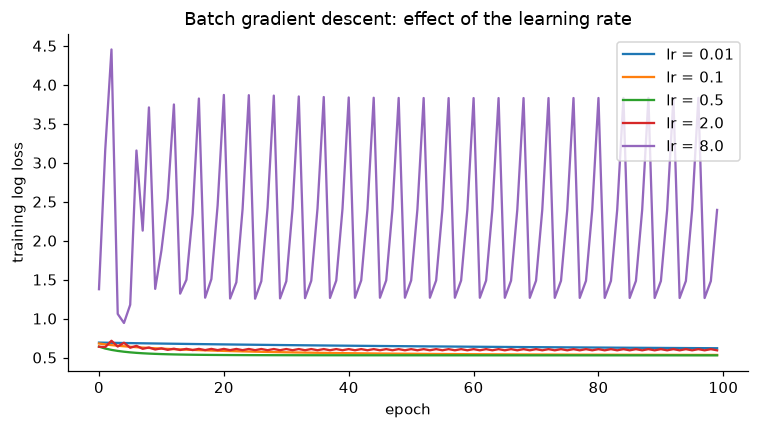

{'0.01': 0.6195, '0.1': 0.5335, '0.5': 0.5282, '2.0': 0.5926, '8.0': 2.3942}

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for lr, losses in curves.items():
    ax.plot(losses, label=f"lr = {lr}")
ax.set(title="Batch gradient descent: effect of the learning rate", xlabel="epoch", ylabel="training log loss"); ax.legend()
fig.tight_layout(); fig.savefig("reports/figures/04_learning_rate.png"); plt.show()
lr_effect = {str(lr): round(float(losses[-1]), 4) for lr, losses in curves.items()}
lr_effect

A small learning rate can converge slowly; a large one can overshoot and oscillate. The full vertical range is shown so unstable runs are visible. Compare the curves and final losses rather than assuming every learning rate converges.

### Regularisation and the bias–variance trade-off
The full logistic-regression baseline uses numeric features **plus one-hot categoricals** from the shared preprocessor. `C` is the inverse of L2 penalty strength: smaller C means stronger regularisation.

Fit on January–August and select C using **September only**. October is a diagnostic column; do not use it to choose C. This sweep is separate from the fixed-parameter rolling comparison below.

In [7]:
import fdp.baselines as bl; importlib.reload(bl)
reg_rows = []
for C in ([0.001, 0.01, 1.0] if QUICK_RUN else [0.0003, 0.001, 0.003, 0.01, 0.1, 1.0]):
    pipe = bl.logistic_regression(NUM, CAT, C).fit(S["train"], y["train"])
    reg_rows.append({"C": C, **{f"{p}_pr_auc": float(ap(y[p], pipe.predict_proba(S[p])[:, 1])) for p in ["train", "valid", "calib"]}})
reg_table = pd.DataFrame(reg_rows)
BEST_C = float(reg_table.loc[reg_table["valid_pr_auc"].idxmax(), "C"])
print("C chosen on September:", BEST_C)
reg_table

C chosen on September: 0.001


,C,train_pr_auc,valid_pr_auc,calib_pr_auc
0,0.0003,0.468404,0.264044,0.306621
1,0.0010,0.471379,0.265461,0.307940
2,0.0030,0.472838,0.264601,0.307646
3,0.0100,0.473595,0.263378,0.307356
4,0.1000,0.473893,0.262802,0.307139
5,1.0000,0.474034,0.262406,0.307272


Inspect the train–September gap as C changes. `BEST_C` records the September choice for the baseline handoff. It is not fed into earlier rolling folds, since that would use future information to choose their settings.

---
## Part C · Phase 8A — Model selection: which family?
Candidates, all with the same features and the same evaluation:

| Model | How it learns | Expected weakness |
|---|---|---|
| Logistic regression | one weighted sum → sigmoid | cannot model interactions like *late hour × busy airport* unless we hand-build them |
| Decision tree (CART) | recursive splits by Gini impurity | one deep tree memorises training data (high variance) |
| Random forest | many trees on bootstrap samples, averaged (**bagging**) | reduces variance; each tree is still deep and slow |
| Gradient boosting (XGBoost, fixed untuned settings) | small trees added one by one, each fixing the previous errors (**boosting**) | needs tuning (notebook 05) |

First, the single tree's overfitting, then all four on **rolling folds**: train on every month before July / August / September, validate on that month. Three months give a fairer comparison than one.

Each fold fits preprocessing on its own training rows. Historical features use outcomes only from days before the prediction date; this simulates daily operation as new outcomes become available. Fixed family settings are declared below independently of the September sweeps. The rolling scores compare those configurations; they are not final test estimates.

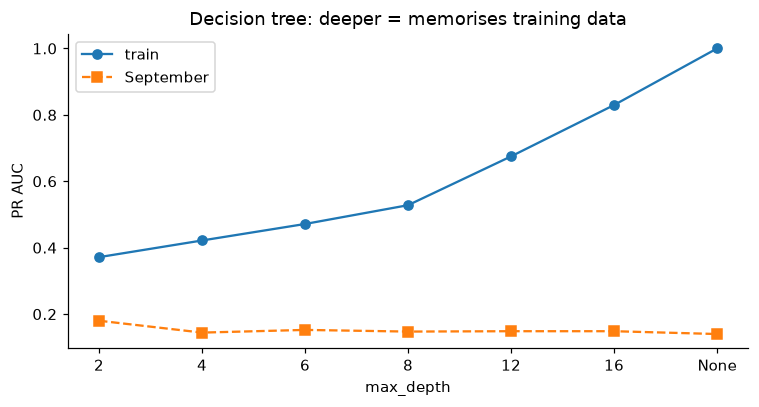

,max_depth,leaves,train_pr_auc,valid_pr_auc
0,2,4,0.3715,0.1801
1,4,16,0.4217,0.1443
2,6,64,0.4714,0.1524
3,8,245,0.5280,0.1474
4,12,2259,0.6750,0.1485
5,16,8744,0.8296,0.1485
6,None,30457,1.0000,0.1400


In [8]:
from sklearn.tree import DecisionTreeClassifier
tree_pre = prep.tree_preprocessor(NUM, CAT).fit(S["train"])
T = {k: tree_pre.transform(v) for k, v in S.items()}
depth_rows = []
for d in [2, 4, 6, 8, 12, 16, None]:
    t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=1, random_state=config.SEED).fit(T["train"], y["train"])
    depth_rows.append({"max_depth": str(d), "leaves": int(t.get_n_leaves()),
                       "train_pr_auc": round(ap(y["train"], t.predict_proba(T["train"])[:, 1]), 4),
                       "valid_pr_auc": round(ap(y["valid"], t.predict_proba(T["valid"])[:, 1]), 4)})
depth_table = pd.DataFrame(depth_rows)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(depth_table["max_depth"], depth_table["train_pr_auc"], "o-", label="train")
ax.plot(depth_table["max_depth"], depth_table["valid_pr_auc"], "s--", label="September")
ax.set(title="Decision tree: deeper = memorises training data", xlabel="max_depth", ylabel="PR AUC"); ax.legend()
fig.tight_layout(); fig.savefig("reports/figures/04_tree_depth.png"); plt.show()
depth_table

Compare how training and September scores change with depth. Increasing training performance without a corresponding validation gain is evidence of overfitting. Bagging reduces variance by averaging trees; boosting fits trees sequentially to improve the current ensemble.

In [9]:
import time, xgboost as xgb
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
lab = X[X["delayed"].notna() & (X["date"] >= config.SPLITS["train"][0]) & (X["date"] <= config.SPLITS["valid"][1])].reset_index(drop=True)
ylab = lab["delayed"].astype(int).to_numpy()
best_depth = depth_table.loc[depth_table["valid_pr_auc"].idxmax(), "max_depth"]
best_depth = None if best_depth == "None" else int(best_depth)

# These fixed configurations never use BEST_C or best_depth from September.
# Tuning the boosting family belongs to notebook 05.
rolling_parameters = {
    "Logistic regression": {"C": 1.0},
    "Decision tree": {"max_depth": 4, "min_samples_leaf": 200},
    "Random forest": {"n_estimators": 50 if QUICK_RUN else 150, "min_samples_leaf": 100,
                      "max_features": "sqrt", "max_samples": 0.5},
    "Gradient boosting (XGBoost, untuned)": {
        "n_estimators": 100 if QUICK_RUN else 300, "learning_rate": 0.1, "max_depth": 6},
}

def make(name):
    params = rolling_parameters[name]
    if name == "Logistic regression":
        return bl.logistic_regression(NUM, CAT, **params)
    if name == "Decision tree":
        estimator = DecisionTreeClassifier(**params, random_state=config.SEED)
    elif name == "Random forest":
        estimator = RandomForestClassifier(**params, n_jobs=4, random_state=config.SEED)
    elif name == "Gradient boosting (XGBoost, untuned)":
        estimator = xgb.XGBClassifier(**params, tree_method="hist", n_jobs=4, random_state=config.SEED)
    else:
        raise ValueError(f"Unknown model: {name}")
    return make_pipeline(prep.tree_preprocessor(NUM, CAT), estimator)

sel_rows, fold_details = [], []
for name in rolling_parameters:
    scores, secs = [], []
    for month in config.CV_MONTHS:
        first = pd.Timestamp(2013, month, 1)
        last = first + pd.offsets.MonthEnd(0)
        tr, va = lab["date"] < first, lab["date"].between(first, last)
        assert lab.loc[tr, "date"].max() < lab.loc[va, "date"].min()
        t0 = time.perf_counter()
        model = make(name).fit(lab.loc[tr], ylab[tr])
        seconds = time.perf_counter() - t0
        score = float(ap(ylab[va], model.predict_proba(lab.loc[va])[:, 1]))
        scores.append(score)
        secs.append(seconds)
        fold_details.append({"model": name, "month": month, "train_rows": int(tr.sum()),
                             "valid_rows": int(va.sum()), "train_end": str(lab.loc[tr, "date"].max().date()),
                             "valid_start": str(first.date()), "pr_auc": score, "fit_seconds": seconds})
    sel_rows.append({"model": name, **{pd.Timestamp(2013, m, 1).strftime("%b"): round(s, 4)
                                      for m, s in zip(config.CV_MONTHS, scores)},
                     "mean_pr_auc": round(float(np.mean(scores)), 4),
                     "fit_seconds": round(float(np.mean(secs)), 2)})
    print(sel_rows[-1])
selection_table = pd.DataFrame(sel_rows)
selection_table

{'model': 'Logistic regression', 'Jul': 0.5566, 'Aug': 0.4058, 'Sep': 0.2624, 'mean_pr_auc': 0.4083, 'fit_seconds': 2.62}


{'model': 'Decision tree', 'Jul': 0.4856, 'Aug': 0.3535, 'Sep': 0.1446, 'mean_pr_auc': 0.3279, 'fit_seconds': 1.44}


{'model': 'Random forest', 'Jul': 0.5542, 'Aug': 0.3887, 'Sep': 0.2157, 'mean_pr_auc': 0.3862, 'fit_seconds': 6.3}


{'model': 'Gradient boosting (XGBoost, untuned)', 'Jul': 0.5591, 'Aug': 0.3692, 'Sep': 0.1695, 'mean_pr_auc': 0.3659, 'fit_seconds': 1.76}


,model,Jul,Aug,Sep,mean_pr_auc,fit_seconds
0,Logistic regression,0.5566,0.4058,0.2624,0.4083,2.62
1,Decision tree,0.4856,0.3535,0.1446,0.3279,1.44
2,Random forest,0.5542,0.3887,0.2157,0.3862,6.30
3,"Gradient boosting (XGBoost, untuned)",0.5591,0.3692,0.1695,0.3659,1.76


### Trade-off table (worksheet Phase 8A: interpretability, accuracy, training time, scalability)

In [10]:
st = selection_table.set_index("model")
tradeoff = pd.DataFrame({
    "mean rolling PR AUC": st["mean_pr_auc"],
    "mean fit time (s)": st["fit_seconds"],
    "interpretability": ["high: coefficients", "high: depth-limited rules", "low: many trees", "medium: tree importance"],
    "handles interactions / non-linearity": ["only if engineered", "yes", "yes", "yes"],
    "missing values in this pipeline": ["median imputation"] * 4,
    "scalability": ["efficient; sparse one-hot inputs", "cheap prediction; limited capacity",
                    "parallel trees; higher memory", "histogram splits; sequential boosting rounds"],
})
# XGBoost also supports missing values natively, but this comparison uses the
# same imputed tree inputs. Ordinal category splits depend on category coding.
tradeoff

,mean rolling PR AUC,mean fit time (s),interpretability,handles interactions / non-linearity,missing values in this pipeline,scalability
model,,,,,,
Logistic regression,0.4083,2.62,high: coefficients,only if engineered,median imputation,efficient; sparse one-hot inputs
Decision tree,0.3279,1.44,high: depth-limited rules,yes,median imputation,cheap prediction; limited capacity
Random forest,0.3862,6.30,low: many trees,yes,median imputation,parallel trees; higher memory
"Gradient boosting (XGBoost, untuned)",0.3659,1.76,medium: tree importance,yes,median imputation,histogram splits; sequential boosting rounds


### Decision (read the table above)
Use mean rolling average precision to compare the fixed candidate configurations, then weigh training time and interpretability. A single configuration does not establish a family's best possible performance.

Logistic regression remains the simple learned baseline for the next stage. Gradient boosting proceeds to notebook 05 for tuning because it is the project's focus; the final held-out evaluation will determine whether its complexity is justified. No final test score or tuned boosting result is produced here.

In [11]:
import platform
from datetime import datetime, timezone
import sklearn
winner = selection_table.loc[selection_table["mean_pr_auc"].idxmax(), "model"]
print("Best fixed configuration on rolling months:", winner)
out = {
    "run": {"quick_run": QUICK_RUN, "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit_learn": sklearn.__version__, "xgboost": xgb.__version__, "seed": config.SEED,
            "split_rows": {k: len(v) for k, v in S.items()}, "test_evaluated": False,
            "metric": "average_precision_score",
            "learning_rate_epochs": EPOCHS},
    "baselines": base, "lr_effect_logloss": lr_effect,
    "regularisation": reg_table.to_dict(orient="records"), "best_C": BEST_C,
    "tree_depth": depth_table.to_dict(orient="records"), "best_tree_depth": str(best_depth),
    "model_selection": selection_table.to_dict(orient="records"),
    "rolling_parameters": rolling_parameters, "rolling_folds": fold_details,
    "tradeoffs": tradeoff.reset_index().to_dict(orient="records"), "best_rolling_model": winner,
    "selection_protocol": "Fixed configurations on Jul/Aug/Sep with fold-local preprocessing; September C/depth sweeps are separate. October is diagnostic only; Nov/Dec are not evaluated.",
}
with open("reports/04_model_selection.json", "w") as f:
    json.dump(out, f, indent=2, allow_nan=False)
print("Saved reports/04_model_selection.json")

Best fixed configuration on rolling months: Logistic regression
Saved reports/04_model_selection.json


---
## Summary
**Recorded full-run findings** (the saved tables and figures above; new runs can differ):

* September average precision was **0.1372** for the constant baseline, **0.1897** for the flight's trailing delay rate, and **0.1883** for scheduled hour.
* In the learning-rate experiment (100 epochs of batch gradient descent), lr 0.01 was still slow at log loss **0.6195**, lr 0.5 reached **0.5282**, and lr 8 oscillated, ending at **2.3942**.
* September selected **C = 0.001** in the regularisation sweep and **depth 2** in the tree-depth sweep. The unlimited tree fit training labels perfectly but generalised poorly.
* Mean rolling average precision ranked logistic regression (**0.4083**), random forest (**0.3862**), untuned XGBoost (**0.3659**) and the fixed-depth tree (**0.3279**) in that order. These folds used fixed settings, independent of the September sweeps.
* Logistic regression is the learned baseline to beat. Notebook 05 owns boosting tuning, calibration and the reserved November–December test evaluation.

<details><summary><b>Viva questions</b></summary>

1. **Why baselines first?** A complex model must justify its extra cost by improving on a simple alternative.
2. **Why log loss?** It is the negative log-likelihood of a Bernoulli label; minimising it without a penalty gives maximum likelihood estimation. L2 adds regularisation.
3. **What is the gradient?** Xᵀ(σ(Xw + b) − y)/n + λw for weights; mean(σ(Xw + b) − y) for the unpenalised intercept.
4. **What does learning rate control?** Step size. Too small can be slow; too large can overshoot.
5. **What is C?** Inverse regularisation strength in scikit-learn; smaller means stronger regularisation.
6. **Why can a deep tree fit training labels perfectly?** It can split down to pure leaves and memorise the observations.
7. **Bagging vs boosting?** Bagging averages independently trained bootstrap trees; boosting adds trees sequentially to improve the current ensemble.
8. **Why rolling months?** They simulate training on the past and predicting the next month across changing delay rates.
9. **Why not use September's best C in the July fold?** That would let future validation labels influence an earlier model choice.
10. **Why tune boosting next?** It is the project focus. Fixed untuned settings do not show its best performance; the reserved test set must judge the final improvement.

</details>

In [12]:
#@title 📦 Last step · download the files you must commit { display-mode: "form" }
#@markdown Downloads a zip with your module(s) and results. Also do **File → Download → Download .ipynb** (keeps the outputs).
#@markdown Unzip both into your local clone of the repo and commit them.
import glob, zipfile
FILES = [
    'src/fdp/baselines.py',
    'reports/04_model_selection.json',
    'reports/figures/04_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "04_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 4 files into 04_outputs.zip
   reports/04_model_selection.json
   reports/figures/04_learning_rate.png
   reports/figures/04_tree_depth.png
   src/fdp/baselines.py
